In [1]:
# Experiment 11: Illumination Drift Detection
# Fresh setup — separate from Experiment 10

import os
import sys
import random
import platform
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path("/content/Experiment_11")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

for directory in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Experiment 11 setup complete.")
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Project directory:", PROJECT_DIR)

Experiment 11 setup complete.
Python: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
NumPy: 2.1.3
Pandas: 2.2.3
Project directory: /content/Experiment_11


In [3]:
# Experiment 11: Install required libraries

%pip install -q torch torchvision scikit-learn scikit-image pillow tqdm

In [4]:
import torch
import torchvision
import sklearn
import skimage
from PIL import Image

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Scikit-image:", skimage.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Experiment 11 library verification passed.")

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
Scikit-learn: 1.6.1
Scikit-image: 0.25.2
CUDA available: False
Experiment 11 library verification passed.


In [5]:
# Experiment 11 — Step 3: Load and verify LFW

from sklearn.datasets import fetch_lfw_people
import numpy as np
import pandas as pd

lfw = fetch_lfw_people(
    min_faces_per_person=20,
    resize=0.5,
    color=True,
    download_if_missing=True
)

images = lfw.images
labels = lfw.target
identity_names = lfw.target_names

print("Dataset verification")
print("-" * 40)
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Number of identities:", len(identity_names))
print("Image height/width:", images.shape[1:3])
print("Pixel range:", float(images.min()), "to", float(images.max()))
print("Missing/non-finite pixels:", int((~np.isfinite(images)).sum()))
print("Missing labels:", int(pd.isna(labels).sum()))
print("Unique identities in loaded dataset:", len(np.unique(labels)))

assert len(images) == len(labels)
assert images.ndim == 4 and images.shape[-1] == 3
assert np.isfinite(images).all()
assert len(np.unique(labels)) >= 2

print("\nLFW dataset verification passed.")

Dataset verification
----------------------------------------
Images shape: (3023, 62, 47, 3)
Labels shape: (3023,)
Number of identities: 62
Image height/width: (62, 47)
Pixel range: 0.0 to 1.0
Missing/non-finite pixels: 0
Missing labels: 0
Unique identities in loaded dataset: 62

LFW dataset verification passed.


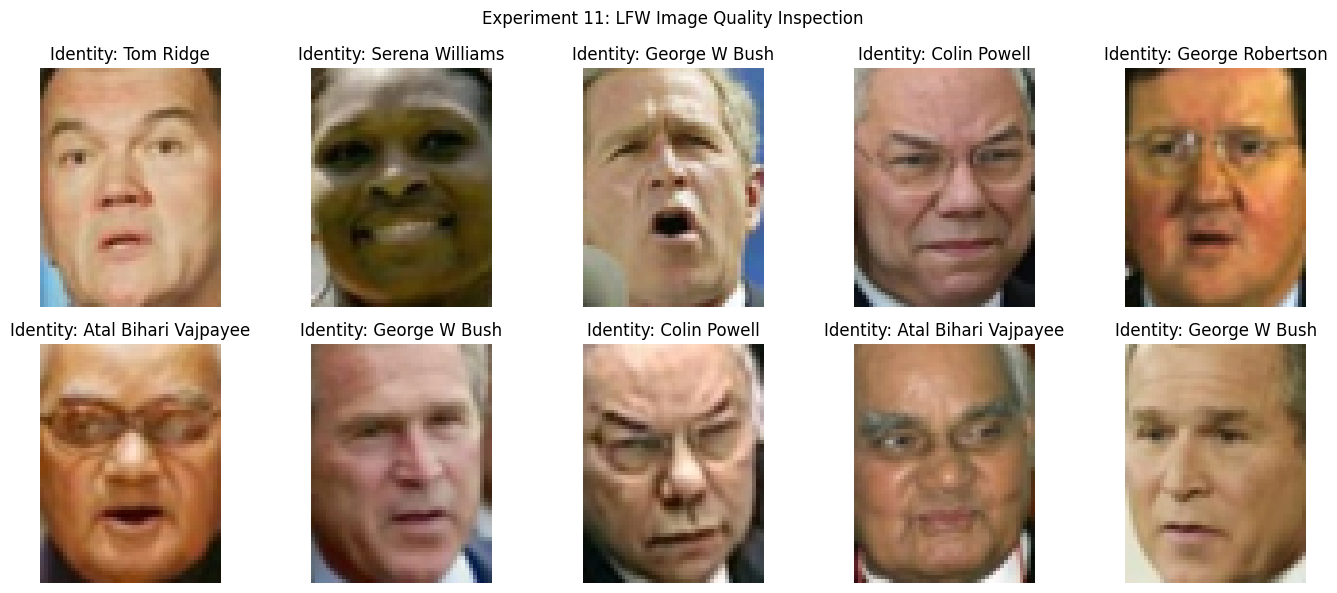

Images inspected: 10
Image dtype: float32
Dataset pixel range: 0.0 to 1.0


In [6]:
# Experiment 11 — Step 4: Visual inspection of LFW images

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

sample_indices = np.random.default_rng(42).choice(
    len(images), size=10, replace=False
)

for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(images[idx])
    ax.set_title(f"Identity: {identity_names[labels[idx]]}")
    ax.axis("off")

plt.suptitle("Experiment 11: LFW Image Quality Inspection")
plt.tight_layout()
plt.show()

print("Images inspected:", len(sample_indices))
print("Image dtype:", images.dtype)
print("Dataset pixel range:", float(images.min()), "to", float(images.max()))

Illumination transformation audit
----------------------------------------
Dim: shape=(3023, 62, 47, 3), mean_pixel=0.2978, min=0.000, max=0.600
Original: shape=(3023, 62, 47, 3), mean_pixel=0.4964, min=0.000, max=1.000
Bright: shape=(3023, 62, 47, 3), mean_pixel=0.6710, min=0.000, max=1.000


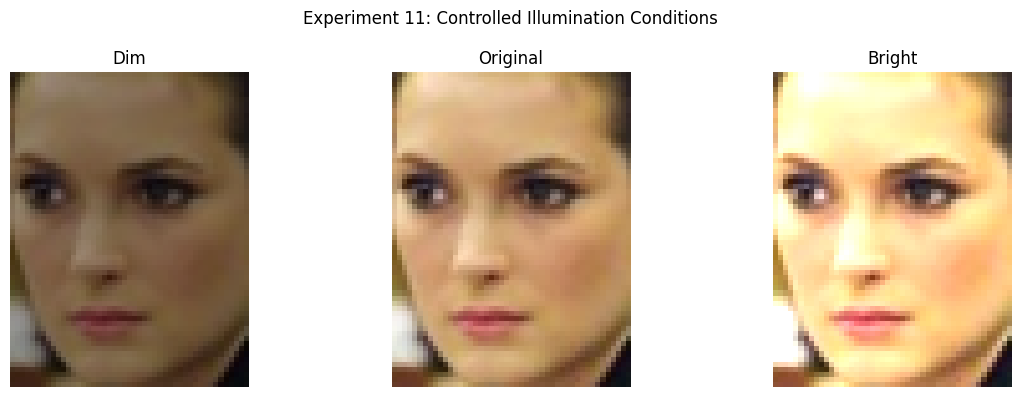


Preview saved to: /content/Experiment_11/figures/experiment11_illumination_preview.png
Transformation audit complete.


In [7]:
# Experiment 11 — Step 5: Controlled illumination transformations

import numpy as np
import matplotlib.pyplot as plt

# Fixed transformations applied consistently to every image
illumination_conditions = {
    "Dim": 0.60,
    "Original": 1.00,
    "Bright": 1.40,
}

illumination_images = {
    name: np.clip(images * factor, 0.0, 1.0).astype(np.float32)
    for name, factor in illumination_conditions.items()
}

# Report average pixel intensity for each condition
print("Illumination transformation audit")
print("-" * 40)

for name, transformed in illumination_images.items():
    print(
        f"{name}: shape={transformed.shape}, "
        f"mean_pixel={transformed.mean():.4f}, "
        f"min={transformed.min():.3f}, "
        f"max={transformed.max():.3f}"
    )

# Visualize one image under all three conditions
sample_idx = 0

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (name, transformed) in zip(
    axes, illumination_images.items()
):
    ax.imshow(transformed[sample_idx])
    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Experiment 11: Controlled Illumination Conditions")
plt.tight_layout()

figure_path = FIGURES_DIR / "experiment11_illumination_preview.png"
plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

print("\nPreview saved to:", figure_path)
print("Transformation audit complete.")

In [8]:
# Experiment 11 — Step 6: ResNet-18 embedding extraction

import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import DataLoader, TensorDataset

# Reproducibility
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Replace classification head with identity to get 512-D features
model.fc = nn.Identity()
model = model.to(device)
model.eval()

# LFW images are small; resize consistently to the model's expected input size.
preprocess = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def extract_embeddings(image_array, batch_size=32):
    processed = torch.stack([
        preprocess(img) for img in image_array
    ])
    loader = DataLoader(
        TensorDataset(processed),
        batch_size=batch_size,
        shuffle=False
    )

    all_embeddings = []
    with torch.inference_mode():
        for (batch,) in loader:
            batch = batch.to(device)
            embeddings = model(batch)
            all_embeddings.append(embeddings.cpu().numpy())

    return np.concatenate(all_embeddings, axis=0).astype(np.float32)

embedding_results = {}

for condition, condition_images in illumination_images.items():
    print(f"Extracting embeddings: {condition}...")
    embedding_results[condition] = extract_embeddings(condition_images)

    print("  Shape:", embedding_results[condition].shape)
    print("  Finite values:", np.isfinite(
        embedding_results[condition]
    ).all())

# Verify the embedding shapes and numerical validity
for condition, embeddings in embedding_results.items():
    assert embeddings.shape == (len(images), 512)
    assert np.isfinite(embeddings).all()

print("\nResNet-18 embedding extraction completed successfully.")
print("Device:", device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 27.8MB/s]


Extracting embeddings: Dim...
  Shape: (3023, 512)
  Finite values: True
Extracting embeddings: Original...
  Shape: (3023, 512)
  Finite values: True
Extracting embeddings: Bright...
  Shape: (3023, 512)
  Finite values: True

ResNet-18 embedding extraction completed successfully.
Device: cpu


In [9]:
# Experiment 11 — Step 7: Save embeddings and audit feature changes

import hashlib
import json
import numpy as np
import pandas as pd

# Save embeddings, labels, and experimental metadata separately
embedding_file = DATA_DIR / "experiment11_resnet18_embeddings.npz"

np.savez_compressed(
    embedding_file,
    dim=embedding_results["Dim"],
    original=embedding_results["Original"],
    bright=embedding_results["Bright"],
    labels=labels,
    identity_names=identity_names,
    seed=SEED,
)

# Compare each transformed embedding with the corresponding original.
original_embeddings = embedding_results["Original"]

audit_rows = []

for condition in ["Dim", "Bright"]:
    changed_embeddings = embedding_results[condition]

    difference = changed_embeddings - original_embeddings
    distances = np.linalg.norm(difference, axis=1)

    original_norms = np.linalg.norm(original_embeddings, axis=1)
    changed_norms = np.linalg.norm(changed_embeddings, axis=1)

    cosine_similarity = np.sum(
        original_embeddings * changed_embeddings, axis=1
    ) / np.maximum(original_norms * changed_norms, 1e-12)

    audit_rows.append({
        "condition": condition,
        "num_images": len(distances),
        "embedding_dimension": changed_embeddings.shape[1],
        "mean_l2_distance": float(distances.mean()),
        "median_l2_distance": float(np.median(distances)),
        "std_l2_distance": float(distances.std()),
        "mean_cosine_similarity": float(cosine_similarity.mean()),
        "min_cosine_similarity": float(cosine_similarity.min()),
        "finite_embeddings": bool(np.isfinite(changed_embeddings).all()),
    })

audit_df = pd.DataFrame(audit_rows)
audit_path = RESULTS_DIR / "experiment11_embedding_shift_audit.csv"
audit_df.to_csv(audit_path, index=False)

# Record reproducibility metadata
metadata = {
    "experiment": "Experiment 11 — Illumination Drift Detection",
    "dataset": "LFW subset with min_faces_per_person=20",
    "num_images": int(len(images)),
    "num_identities": int(len(identity_names)),
    "embedding_model": "ImageNet-pretrained ResNet-18, classification head removed",
    "embedding_dimension": 512,
    "illumination_factors": illumination_conditions,
    "seed": SEED,
    "device": str(device),
}

metadata_path = RESULTS_DIR / "experiment11_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2))

print("Embedding file saved:", embedding_file)
print("Embedding file size (MB):", round(embedding_file.stat().st_size / 1e6, 2))
print("\nEmbedding shift audit:")
display(audit_df.round(5))

print("\nMetadata saved:", metadata_path)
print("Audit CSV saved:", audit_path)
print("\nStep 7 completed.")

Embedding file saved: /content/Experiment_11/data/experiment11_resnet18_embeddings.npz
Embedding file size (MB): 16.64

Embedding shift audit:


,condition,num_images,embedding_dimension,mean_l2_distance,median_l2_distance,std_l2_distance,mean_cosine_similarity,min_cosine_similarity,finite_embeddings
0,Dim,3023,512,4.08922,3.96560,0.78472,0.97959,0.92852,True
1,Bright,3023,512,5.61621,5.34689,1.90185,0.95689,0.78815,True



Metadata saved: /content/Experiment_11/results/experiment11_metadata.json
Audit CSV saved: /content/Experiment_11/results/experiment11_embedding_shift_audit.csv

Step 7 completed.


In [10]:
# Experiment 11 — Step 8: Identity-disjoint data splits

from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# Split identity labels into reference, calibration, and evaluation groups.
unique_ids = np.unique(labels)

ref_ids, remaining_ids = train_test_split(
    unique_ids, test_size=0.40, random_state=SEED
)

cal_ids, eval_ids = train_test_split(
    remaining_ids, test_size=0.50, random_state=SEED
)

ref_mask = np.isin(labels, ref_ids)
cal_mask = np.isin(labels, cal_ids)
eval_mask = np.isin(labels, eval_ids)

# Save image indices so all conditions use the same identity partitions.
split_indices = {
    "reference": np.where(ref_mask)[0],
    "calibration": np.where(cal_mask)[0],
    "evaluation": np.where(eval_mask)[0],
}

# Verify no identity overlaps between partitions.
assert set(ref_ids).isdisjoint(set(cal_ids))
assert set(ref_ids).isdisjoint(set(eval_ids))
assert set(cal_ids).isdisjoint(set(eval_ids))

split_summary = pd.DataFrame([
    {
        "partition": name,
        "num_images": len(indices),
        "num_identities": len(np.unique(labels[indices])),
    }
    for name, indices in split_indices.items()
])

split_path = RESULTS_DIR / "experiment11_identity_split_summary.csv"
split_summary.to_csv(split_path, index=False)

print("Identity-disjoint split summary:")
display(split_summary)

print("Identity overlap checks: PASSED")
print("Split summary saved:", split_path)

Identity-disjoint split summary:


,partition,num_images,num_identities
0,reference,2101,37
1,calibration,523,12
2,evaluation,399,13


Identity overlap checks: PASSED
Split summary saved: /content/Experiment_11/results/experiment11_identity_split_summary.csv


In [11]:
# Experiment 11 — Step 9: Reference baseline and threshold calibration

import numpy as np
import pandas as pd

from scipy.spatial.distance import cdist

# Extract original-condition embeddings for each identity partition
ref_idx = split_indices["reference"]
cal_idx = split_indices["calibration"]
eval_idx = split_indices["evaluation"]

X_ref = embedding_results["Original"][ref_idx]
X_cal = embedding_results["Original"][cal_idx]

# Fit standardization using reference data only
feature_mean = X_ref.mean(axis=0)
feature_std = X_ref.std(axis=0)
feature_std[feature_std < 1e-8] = 1.0

def standardize(X):
    return (X - feature_mean) / feature_std

Z_ref = standardize(X_ref)
Z_cal = standardize(X_cal)

# Use reference centroid and covariance for detector statistics
reference_centroid = Z_ref.mean(axis=0)

# Regularized inverse covariance matrices
ridge_values = [0.001, 0.01, 0.1]
covariance = np.cov(Z_ref, rowvar=False)

inverse_covariances = {
    ridge: np.linalg.pinv(
        covariance + ridge * np.eye(covariance.shape[0])
    )
    for ridge in ridge_values
}

def calculate_scores(X):
    Z = standardize(X)

    euclidean = np.linalg.norm(
        Z - reference_centroid, axis=1
    )

    scores = {"euclidean": euclidean}

    for ridge, inverse_cov in inverse_covariances.items():
        delta = Z - reference_centroid
        mahalanobis_sq = np.einsum(
            "ij,jk,ik->i", delta, inverse_cov, delta
        )
        scores[f"mahalanobis_ridge_{ridge}"] = np.sqrt(
            np.maximum(mahalanobis_sq, 0)
        )

    return scores

calibration_scores = calculate_scores(X_cal)

# Non-overlapping calibration windows
WINDOW_SIZE = 20
QUANTILE = 0.95

def window_scores(scores, window_size=WINDOW_SIZE):
    n_windows = len(scores) // window_size
    trimmed = scores[:n_windows * window_size]
    return trimmed.reshape(n_windows, window_size).mean(axis=1)

threshold_rows = []
thresholds = {}

for detector_name, scores in calibration_scores.items():
    per_window = window_scores(scores)

    if len(per_window) < 5:
        raise ValueError(
            f"Too few calibration windows for {detector_name}: "
            f"{len(per_window)}"
        )

    threshold = float(
        np.quantile(per_window, QUANTILE, method="higher")
    )
    thresholds[detector_name] = threshold

    threshold_rows.append({
        "detector": detector_name,
        "calibration_windows": len(per_window),
        "quantile": QUANTILE,
        "threshold": threshold,
    })

threshold_df = pd.DataFrame(threshold_rows)
threshold_path = RESULTS_DIR / "experiment11_thresholds.csv"
threshold_df.to_csv(threshold_path, index=False)

print("Threshold calibration completed.")
display(threshold_df.round(5))
print("Thresholds saved:", threshold_path)

Threshold calibration completed.


,detector,calibration_windows,quantile,threshold
0,euclidean,26,0.95,23.68403
1,mahalanobis_ridge_0.001,26,0.95,28.69808
2,mahalanobis_ridge_0.01,26,0.95,27.29624
3,mahalanobis_ridge_0.1,26,0.95,21.56594


Thresholds saved: /content/Experiment_11/results/experiment11_thresholds.csv


In [12]:
# Experiment 11 — Step 10: Build controlled evaluation streams

import numpy as np
import pandas as pd

eval_idx = split_indices["evaluation"]

# Stable order: preserve the same image order across all conditions.
eval_idx = np.sort(eval_idx)

# Keep original and transformed versions of the exact same images.
stream_embeddings = {
    "control": embedding_results["Original"][eval_idx],
    "dim_drift": embedding_results["Dim"][eval_idx],
    "bright_drift": embedding_results["Bright"][eval_idx],
}

# Construct windows from image-level embeddings.
WINDOW_SIZE = 20

def make_window_matrix(X, window_size=WINDOW_SIZE):
    n_windows = len(X) // window_size
    if n_windows < 2:
        raise ValueError("Not enough samples for window construction.")
    return X[:n_windows * window_size].reshape(
        n_windows, window_size, X.shape[1]
    )

# Drift begins at the midpoint of the window sequence.
windowed_streams = {
    name: make_window_matrix(X)
    for name, X in stream_embeddings.items()
}

for name, W in windowed_streams.items():
    print(
        f"{name}: {W.shape[0]} windows, "
        f"{W.shape[1]} images/window, "
        f"{W.shape[2]} embedding dimensions"
    )

print("\nControlled streams created.")

control: 19 windows, 20 images/window, 512 embedding dimensions
dim_drift: 19 windows, 20 images/window, 512 embedding dimensions
bright_drift: 19 windows, 20 images/window, 512 embedding dimensions

Controlled streams created.


In [13]:
# Experiment 11 — Step 11: Controlled illumination transitions

import numpy as np
import pandas as pd

eval_idx = np.sort(split_indices["evaluation"])

X_original = embedding_results["Original"][eval_idx]
X_dim = embedding_results["Dim"][eval_idx]
X_bright = embedding_results["Bright"][eval_idx]

WINDOW_SIZE = 20
DRIFT_START_WINDOW = 9

def build_transition_stream(X_base, X_drift):
    # Keep image order consistent; transition occurs at window boundary.
    X = X_base.copy()
    start = DRIFT_START_WINDOW * WINDOW_SIZE
    X[start:] = X_drift[start:]
    n_windows = len(X) // WINDOW_SIZE
    return X[:n_windows * WINDOW_SIZE].reshape(
        n_windows, WINDOW_SIZE, X.shape[1]
    )

transition_streams = {
    "control": X_original[:(len(X_original)//WINDOW_SIZE)*WINDOW_SIZE]
        .reshape(-1, WINDOW_SIZE, X_original.shape[1]),
    "dim_drift": build_transition_stream(X_original, X_dim),
    "bright_drift": build_transition_stream(X_original, X_bright),
}

def score_window_embeddings(W):
    # Average embeddings within each window, then use the fixed
    # reference standardization and detector thresholds.
    means = W.mean(axis=1)
    scores = calculate_scores(means)
    return scores

result_rows = []

for stream_name, W in transition_streams.items():
    scores_by_detector = score_window_embeddings(W)

    for detector_name, scores in scores_by_detector.items():
        threshold = thresholds[detector_name]
        alarms = scores > threshold

        pre_alarms = int(alarms[:DRIFT_START_WINDOW].sum())
        post_alarms = int(alarms[DRIFT_START_WINDOW:].sum())

        result_rows.append({
            "stream": stream_name,
            "detector": detector_name,
            "threshold": threshold,
            "total_windows": len(scores),
            "pre_drift_alarms": pre_alarms,
            "post_drift_alarms": post_alarms,
            "first_post_drift_alarm_window": (
                int(np.where(alarms[DRIFT_START_WINDOW:])[0][0]
                    + DRIFT_START_WINDOW)
                if alarms[DRIFT_START_WINDOW:].any() else None
            ),
            "post_drift_detection": bool(
                alarms[DRIFT_START_WINDOW:].any()
            ),
        })

results_df = pd.DataFrame(result_rows)
results_path = RESULTS_DIR / "experiment11_controlled_detection_results.csv"
results_df.to_csv(results_path, index=False)

display(results_df)
print("Results saved:", results_path)
print("Step 11 completed.")

,stream,detector,threshold,total_windows,pre_drift_alarms,post_drift_alarms,first_post_drift_alarm_window,post_drift_detection
0,control,euclidean,23.684032,19,0,0,None,False
1,control,mahalanobis_ridge_0.001,28.698076,19,0,0,None,False
2,control,mahalanobis_ridge_0.01,27.296239,19,0,0,None,False
3,control,mahalanobis_ridge_0.1,21.565942,19,0,0,None,False
4,dim_drift,euclidean,23.684032,19,0,0,None,False
5,dim_drift,mahalanobis_ridge_0.001,28.698076,19,0,0,None,False
6,dim_drift,mahalanobis_ridge_0.01,27.296239,19,0,0,None,False
7,dim_drift,mahalanobis_ridge_0.1,21.565942,19,0,0,None,False
8,bright_drift,euclidean,23.684032,19,0,0,None,False
9,bright_drift,mahalanobis_ridge_0.001,28.698076,19,0,0,None,False


Results saved: /content/Experiment_11/results/experiment11_controlled_detection_results.csv
Step 11 completed.


In [14]:
# Experiment 11 — Step 12: Detector score diagnostics

diagnostic_rows = []

for stream_name, W in transition_streams.items():
    scores_by_detector = score_window_embeddings(W)

    for detector_name, scores in scores_by_detector.items():
        threshold = thresholds[detector_name]

        diagnostic_rows.append({
            "stream": stream_name,
            "detector": detector_name,
            "threshold": threshold,
            "min_score": float(np.min(scores)),
            "max_score": float(np.max(scores)),
            "mean_score": float(np.mean(scores)),
            "max_threshold_ratio": float(np.max(scores) / threshold),
            "windows_above_threshold": int(np.sum(scores > threshold)),
        })

diagnostic_df = pd.DataFrame(diagnostic_rows)
diagnostic_path = RESULTS_DIR / "experiment11_score_diagnostics.csv"
diagnostic_df.to_csv(diagnostic_path, index=False)

display(diagnostic_df.round(4))
print("Diagnostics saved:", diagnostic_path)

,stream,detector,threshold,min_score,max_score,mean_score,max_threshold_ratio,windows_above_threshold
0,control,euclidean,23.6840,4.3417,7.5026,5.7628,0.3168,0
1,control,mahalanobis_ridge_0.001,28.6981,5.7869,8.1102,6.7632,0.2826,0
2,control,mahalanobis_ridge_0.01,27.2962,5.5178,7.7178,6.4361,0.2827,0
3,control,mahalanobis_ridge_0.1,21.5659,4.3868,6.1033,5.1214,0.2830,0
4,dim_drift,euclidean,23.6840,4.6713,8.7837,6.9659,0.3709,0
5,dim_drift,mahalanobis_ridge_0.001,28.6981,5.7869,8.9279,7.5303,0.3111,0
6,dim_drift,mahalanobis_ridge_0.01,27.2962,5.5178,8.5187,7.1914,0.3121,0
7,dim_drift,mahalanobis_ridge_0.1,21.5659,4.3917,6.9428,5.8080,0.3219,0
8,bright_drift,euclidean,23.6840,4.6713,11.0364,8.1267,0.4660,0
9,bright_drift,mahalanobis_ridge_0.001,28.6981,5.7869,11.7752,8.9263,0.4103,0


Diagnostics saved: /content/Experiment_11/results/experiment11_score_diagnostics.csv


In [15]:
# Experiment 11 — Step 13: Consistent window-level calibration

import numpy as np
import pandas as pd

# Standardized calibration embeddings, preserving current calibration order
calibration_window_count = len(Z_cal) // WINDOW_SIZE

Z_cal_trimmed = Z_cal[
    :calibration_window_count * WINDOW_SIZE
]

Z_cal_windows = Z_cal_trimmed.reshape(
    calibration_window_count, WINDOW_SIZE, Z_cal.shape[1]
)

# Score the mean embedding of each calibration window
calibration_window_means = Z_cal_windows.mean(axis=1)

calibration_window_scores = calculate_scores(
    # Convert standardized window means back to the original
    # embedding scale because calculate_scores standardizes internally.
    calibration_window_means * feature_std + feature_mean
)

consistent_thresholds = {}
threshold_rows = []

for detector_name, scores in calibration_window_scores.items():
    threshold = float(
        np.quantile(scores, 0.95, method="higher")
    )

    consistent_thresholds[detector_name] = threshold

    threshold_rows.append({
        "detector": detector_name,
        "calibration_windows": len(scores),
        "quantile": 0.95,
        "threshold": threshold,
    })

consistent_threshold_df = pd.DataFrame(threshold_rows)

consistent_threshold_path = (
    RESULTS_DIR / "experiment11_consistent_window_thresholds.csv"
)
consistent_threshold_df.to_csv(
    consistent_threshold_path, index=False
)

display(consistent_threshold_df.round(5))
print("Saved:", consistent_threshold_path)
print("Consistent window-level calibration completed.")

,detector,calibration_windows,quantile,threshold
0,euclidean,26,0.95,6.90539
1,mahalanobis_ridge_0.001,26,0.95,7.59231
2,mahalanobis_ridge_0.01,26,0.95,7.16608
3,mahalanobis_ridge_0.1,26,0.95,5.59362


Saved: /content/Experiment_11/results/experiment11_consistent_window_thresholds.csv
Consistent window-level calibration completed.


In [16]:
# Experiment 11 — Step 14: Re-evaluation with consistent thresholds

result_rows = []

for stream_name, W in transition_streams.items():
    scores_by_detector = score_window_embeddings(W)

    for detector_name, scores in scores_by_detector.items():
        threshold = consistent_thresholds[detector_name]
        alarms = scores > threshold

        pre_alarms = int(alarms[:DRIFT_START_WINDOW].sum())
        post_alarms = int(alarms[DRIFT_START_WINDOW:].sum())

        post_indices = np.where(
            alarms[DRIFT_START_WINDOW:]
        )[0]

        first_alarm = (
            int(post_indices[0] + DRIFT_START_WINDOW)
            if len(post_indices) else None
        )

        result_rows.append({
            "stream": stream_name,
            "detector": detector_name,
            "threshold": threshold,
            "pre_drift_alarms": pre_alarms,
            "post_drift_alarms": post_alarms,
            "post_drift_detection": bool(len(post_indices)),
            "first_post_drift_alarm_window": first_alarm,
            "detection_delay_windows": (
                first_alarm - DRIFT_START_WINDOW
                if first_alarm is not None else None
            ),
        })

updated_results = pd.DataFrame(result_rows)

updated_results_path = (
    RESULTS_DIR / "experiment11_corrected_detection_results.csv"
)
updated_results.to_csv(updated_results_path, index=False)

display(updated_results)
print("Saved:", updated_results_path)
print("Corrected evaluation completed.")

,stream,detector,threshold,pre_drift_alarms,post_drift_alarms,post_drift_detection,first_post_drift_alarm_window,detection_delay_windows
0,control,euclidean,6.905388,2,0,False,NaN,NaN
1,control,mahalanobis_ridge_0.001,7.592309,2,0,False,NaN,NaN
2,control,mahalanobis_ridge_0.01,7.166080,3,0,False,NaN,NaN
3,control,mahalanobis_ridge_0.1,5.593615,3,0,False,NaN,NaN
4,dim_drift,euclidean,6.905388,2,10,True,9.0,0.0
5,dim_drift,mahalanobis_ridge_0.001,7.592309,2,8,True,9.0,0.0
6,dim_drift,mahalanobis_ridge_0.01,7.166080,3,9,True,9.0,0.0
7,dim_drift,mahalanobis_ridge_0.1,5.593615,3,10,True,9.0,0.0
8,bright_drift,euclidean,6.905388,2,10,True,9.0,0.0
9,bright_drift,mahalanobis_ridge_0.001,7.592309,2,10,True,9.0,0.0


Saved: /content/Experiment_11/results/experiment11_corrected_detection_results.csv
Corrected evaluation completed.


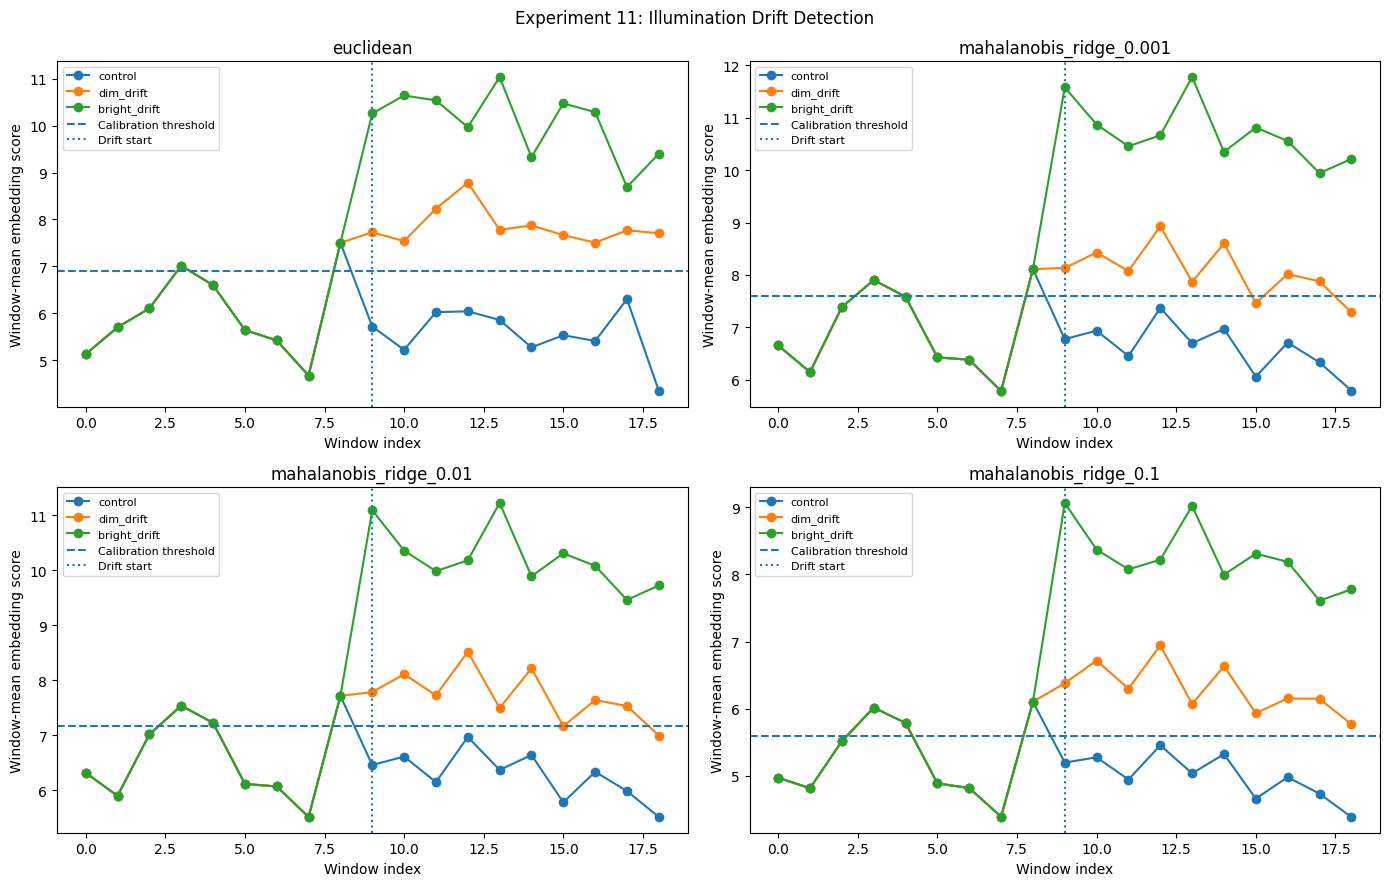

Figure saved: /content/Experiment_11/figures/experiment11_detector_score_timeline.png


In [17]:
# Experiment 11 — Step 16: Plot detector scores and thresholds

import matplotlib.pyplot as plt
import pandas as pd

plot_rows = []

for stream_name, W in transition_streams.items():
    scores_by_detector = score_window_embeddings(W)

    for detector_name, scores in scores_by_detector.items():
        for window_idx, score in enumerate(scores):
            plot_rows.append({
                "stream": stream_name,
                "detector": detector_name,
                "window": window_idx,
                "score": float(score),
                "threshold": consistent_thresholds[detector_name],
            })

plot_df = pd.DataFrame(plot_rows)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, detector_name in zip(axes, consistent_thresholds.keys()):
    subset = plot_df[plot_df["detector"] == detector_name]

    for stream_name in ["control", "dim_drift", "bright_drift"]:
        stream_data = subset[subset["stream"] == stream_name]
        ax.plot(
            stream_data["window"],
            stream_data["score"],
            marker="o",
            label=stream_name
        )

    threshold = consistent_thresholds[detector_name]
    ax.axhline(
        threshold,
        linestyle="--",
        label="Calibration threshold"
    )
    ax.axvline(
        DRIFT_START_WINDOW,
        linestyle=":",
        label="Drift start"
    )
    ax.set_title(detector_name)
    ax.set_xlabel("Window index")
    ax.set_ylabel("Window-mean embedding score")
    ax.legend(fontsize=8)

plt.suptitle("Experiment 11: Illumination Drift Detection")
plt.tight_layout()

figure_path = FIGURES_DIR / "experiment11_detector_score_timeline.png"
plt.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)

In [18]:
# Experiment 11 — Step 17: Calculate alarm-rate metrics

import pandas as pd
from pathlib import Path

results_path = (
    RESULTS_DIR / "experiment11_corrected_detection_results.csv"
)

results_df = pd.read_csv(results_path)

print("Available columns:")
print(results_df.columns.tolist())

display(results_df)

Available columns:
['stream', 'detector', 'threshold', 'pre_drift_alarms', 'post_drift_alarms', 'post_drift_detection', 'first_post_drift_alarm_window', 'detection_delay_windows']


,stream,detector,threshold,pre_drift_alarms,post_drift_alarms,post_drift_detection,first_post_drift_alarm_window,detection_delay_windows
0,control,euclidean,6.905388,2,0,False,NaN,NaN
1,control,mahalanobis_ridge_0.001,7.592309,2,0,False,NaN,NaN
2,control,mahalanobis_ridge_0.01,7.166080,3,0,False,NaN,NaN
3,control,mahalanobis_ridge_0.1,5.593615,3,0,False,NaN,NaN
4,dim_drift,euclidean,6.905388,2,10,True,9.0,0.0
5,dim_drift,mahalanobis_ridge_0.001,7.592309,2,8,True,9.0,0.0
6,dim_drift,mahalanobis_ridge_0.01,7.166080,3,9,True,9.0,0.0
7,dim_drift,mahalanobis_ridge_0.1,5.593615,3,10,True,9.0,0.0
8,bright_drift,euclidean,6.905388,2,10,True,9.0,0.0
9,bright_drift,mahalanobis_ridge_0.001,7.592309,2,10,True,9.0,0.0


In [19]:

# Experiment 11 — Step 17B: Calculate and save alarm-rate metrics

import pandas as pd

results_df = pd.read_csv(
    RESULTS_DIR / "experiment11_corrected_detection_results.csv"
)

N_PRE_WINDOWS = DRIFT_START_WINDOW       # 9
N_POST_WINDOWS = 19 - DRIFT_START_WINDOW # 10

metrics_df = results_df.copy()

metrics_df["pre_drift_false_alarm_rate"] = (
    metrics_df["pre_drift_alarms"] / N_PRE_WINDOWS
)

metrics_df["post_drift_detection_rate"] = (
    metrics_df["post_drift_alarms"] / N_POST_WINDOWS
)

# Detection rate is not applicable to the unchanged control stream.
metrics_df.loc[
    metrics_df["stream"] == "control",
    "post_drift_detection_rate"
] = float("nan")

metrics_df["pre_drift_false_alarm_percent"] = (
    metrics_df["pre_drift_false_alarm_rate"] * 100
).round(2)

metrics_df["post_drift_detection_percent"] = (
    metrics_df["post_drift_detection_rate"] * 100
).round(2)

output_path = (
    RESULTS_DIR / "experiment11_alarm_rate_metrics.csv"
)

metrics_df.to_csv(output_path, index=False)

display(
    metrics_df[
        [
            "stream",
            "detector",
            "pre_drift_alarms",
            "pre_drift_false_alarm_percent",
            "post_drift_alarms",
            "post_drift_detection_percent",
            "detection_delay_windows",
        ]
    ]
)

print("Metrics saved to:", output_path)


,stream,detector,pre_drift_alarms,pre_drift_false_alarm_percent,post_drift_alarms,post_drift_detection_percent,detection_delay_windows
0,control,euclidean,2,22.22,0,NaN,NaN
1,control,mahalanobis_ridge_0.001,2,22.22,0,NaN,NaN
2,control,mahalanobis_ridge_0.01,3,33.33,0,NaN,NaN
3,control,mahalanobis_ridge_0.1,3,33.33,0,NaN,NaN
4,dim_drift,euclidean,2,22.22,10,100.0,0.0
5,dim_drift,mahalanobis_ridge_0.001,2,22.22,8,80.0,0.0
6,dim_drift,mahalanobis_ridge_0.01,3,33.33,9,90.0,0.0
7,dim_drift,mahalanobis_ridge_0.1,3,33.33,10,100.0,0.0
8,bright_drift,euclidean,2,22.22,10,100.0,0.0
9,bright_drift,mahalanobis_ridge_0.001,2,22.22,10,100.0,0.0


Metrics saved to: /content/Experiment_11/results/experiment11_alarm_rate_metrics.csv


In [21]:
# Experiment 11 — Step 18A: Verify inputs for order-sensitivity analysis

# Map correct variable names from the current session
eval_indices = split_indices["evaluation"]
embeddings_by_condition = embedding_results

required_variables = [
    "eval_indices",
    "embeddings_by_condition",
    "transition_streams",
    "WINDOW_SIZE",
    "DRIFT_START_WINDOW",
    "consistent_thresholds",
    "score_window_embeddings",
    "RESULTS_DIR",
]

for variable in required_variables:
    print(f"{variable}: {'available' if variable in globals() else 'MISSING'}")

print("\nEvaluation image count:", len(eval_indices))
print("Window size:", WINDOW_SIZE)
print("Drift start window:", DRIFT_START_WINDOW)
print("Existing streams:", list(transition_streams.keys()))

eval_indices: available
embeddings_by_condition: available
transition_streams: available
WINDOW_SIZE: available
DRIFT_START_WINDOW: available
consistent_thresholds: available
score_window_embeddings: available
RESULTS_DIR: available

Evaluation image count: 399
Window size: 20
Drift start window: 9
Existing streams: ['control', 'dim_drift', 'bright_drift']


In [22]:

# Experiment 11 — Step 18B: Randomized-order sensitivity analysis

import numpy as np
import pandas as pd

ORDER_SENSITIVITY_SEED = 2026
rng = np.random.default_rng(ORDER_SENSITIVITY_SEED)

# Randomize image order once; use exactly the same order for all conditions.
permutation = rng.permutation(len(eval_indices))

randomized_indices = np.asarray(eval_indices)[permutation]

# Retrieve the corresponding embeddings in the randomized order.
randomized_original = np.asarray(
    embeddings_by_condition["Original"]
)[randomized_indices]

randomized_dim = np.asarray(
    embeddings_by_condition["Dim"]
)[randomized_indices]

randomized_bright = np.asarray(
    embeddings_by_condition["Bright"]
)[randomized_indices]

# Retain only complete windows, matching the original analysis.
n_windows = len(randomized_indices) // WINDOW_SIZE
n_used = n_windows * WINDOW_SIZE

randomized_original = randomized_original[:n_used]
randomized_dim = randomized_dim[:n_used]
randomized_bright = randomized_bright[:n_used]

control_randomized = randomized_original.reshape(
    n_windows, WINDOW_SIZE, -1
)

dim_randomized = randomized_original.copy()
dim_randomized[DRIFT_START_WINDOW * WINDOW_SIZE:] = (
    randomized_dim[DRIFT_START_WINDOW * WINDOW_SIZE:]
)
dim_randomized = dim_randomized.reshape(
    n_windows, WINDOW_SIZE, -1
)

bright_randomized = randomized_original.copy()
bright_randomized[DRIFT_START_WINDOW * WINDOW_SIZE:] = (
    randomized_bright[DRIFT_START_WINDOW * WINDOW_SIZE:]
)
bright_randomized = bright_randomized.reshape(
    n_windows, WINDOW_SIZE, -1
)

randomized_transition_streams = {
    "control_randomized": control_randomized,
    "dim_drift_randomized": dim_randomized,
    "bright_drift_randomized": bright_randomized,
}

print("Random seed:", ORDER_SENSITIVITY_SEED)
print("Images available:", len(eval_indices))
print("Images used:", n_used)
print("Windows:", n_windows)
print("Drift starts at window:", DRIFT_START_WINDOW)

for name, stream in randomized_transition_streams.items():
    print(name, stream.shape)

assert all(
    stream.shape == (n_windows, WINDOW_SIZE, 512)
    for stream in randomized_transition_streams.values()
)

print("\nRandomized streams built successfully.")


Random seed: 2026
Images available: 399
Images used: 380
Windows: 19
Drift starts at window: 9
control_randomized (19, 20, 512)
dim_drift_randomized (19, 20, 512)
bright_drift_randomized (19, 20, 512)

Randomized streams built successfully.


In [23]:

# Experiment 11 — Step 18C: Score randomized streams

randomized_results = []

for stream_name, W in randomized_transition_streams.items():
    scores_by_detector = score_window_embeddings(W)

    for detector_name, scores in scores_by_detector.items():
        threshold = consistent_thresholds[detector_name]
        alarms = np.asarray(scores) > threshold

        pre_alarms = int(alarms[:DRIFT_START_WINDOW].sum())
        post_alarms = int(alarms[DRIFT_START_WINDOW:].sum())

        post_alarm_indices = np.where(
            alarms[DRIFT_START_WINDOW:]
        )[0]

        detected = len(post_alarm_indices) > 0

        first_alarm_window = (
            int(DRIFT_START_WINDOW + post_alarm_indices[0])
            if detected else np.nan
        )

        randomized_results.append({
            "stream": stream_name,
            "detector": detector_name,
            "threshold": float(threshold),
            "pre_drift_alarms": pre_alarms,
            "pre_drift_false_alarm_percent": round(
                100 * pre_alarms / DRIFT_START_WINDOW, 2
            ),
            "post_drift_alarms": post_alarms,
            "post_drift_detection_percent": (
                round(100 * post_alarms / (
                    len(alarms) - DRIFT_START_WINDOW
                ), 2)
                if stream_name != "control_randomized"
                else np.nan
            ),
            "post_drift_detection": (
                detected if stream_name != "control_randomized"
                else False
            ),
            "first_post_drift_alarm_window": first_alarm_window,
            "detection_delay_windows": (
                first_alarm_window - DRIFT_START_WINDOW
                if detected and stream_name != "control_randomized"
                else np.nan
            ),
        })

randomized_results_df = pd.DataFrame(randomized_results)

randomized_results_path = (
    RESULTS_DIR / "experiment11_randomized_order_results.csv"
)
randomized_results_df.to_csv(randomized_results_path, index=False)

display(randomized_results_df)

print("Randomized-order results saved to:", randomized_results_path)


,stream,detector,threshold,pre_drift_alarms,pre_drift_false_alarm_percent,post_drift_alarms,post_drift_detection_percent,post_drift_detection,first_post_drift_alarm_window,detection_delay_windows
0,control_randomized,euclidean,6.905388,1,11.11,1,NaN,False,10,NaN
1,control_randomized,mahalanobis_ridge_0.001,7.592309,4,44.44,2,NaN,False,14,NaN
2,control_randomized,mahalanobis_ridge_0.01,7.166080,4,44.44,2,NaN,False,14,NaN
3,control_randomized,mahalanobis_ridge_0.1,5.593615,5,55.56,1,NaN,False,18,NaN
4,dim_drift_randomized,euclidean,6.905388,1,11.11,10,100.0,True,9,0.0
5,dim_drift_randomized,mahalanobis_ridge_0.001,7.592309,4,44.44,10,100.0,True,9,0.0
6,dim_drift_randomized,mahalanobis_ridge_0.01,7.166080,4,44.44,10,100.0,True,9,0.0
7,dim_drift_randomized,mahalanobis_ridge_0.1,5.593615,5,55.56,10,100.0,True,9,0.0
8,bright_drift_randomized,euclidean,6.905388,1,11.11,10,100.0,True,9,0.0
9,bright_drift_randomized,mahalanobis_ridge_0.001,7.592309,4,44.44,10,100.0,True,9,0.0


Randomized-order results saved to: /content/Experiment_11/results/experiment11_randomized_order_results.csv


In [24]:

# Experiment 11 — Step 19: Compare control score distributions

import numpy as np
import pandas as pd

comparison_rows = []

control_streams_for_comparison = {
    "original_order": transition_streams["control"],
    "randomized_order": randomized_transition_streams[
        "control_randomized"
    ],
}

for order_name, W in control_streams_for_comparison.items():
    scores_by_detector = score_window_embeddings(W)

    for detector_name, scores in scores_by_detector.items():
        scores = np.asarray(scores, dtype=float)
        threshold = float(consistent_thresholds[detector_name])
        alarms = scores > threshold

        comparison_rows.append({
            "order": order_name,
            "detector": detector_name,
            "threshold": threshold,
            "mean_control_score": float(np.mean(scores)),
            "median_control_score": float(np.median(scores)),
            "max_control_score": float(np.max(scores)),
            "control_windows_over_threshold": int(alarms.sum()),
            "control_alarm_rate_all_windows_percent": round(
                100 * alarms.mean(), 2
            ),
        })

control_comparison_df = pd.DataFrame(comparison_rows)

comparison_path = (
    RESULTS_DIR / "experiment11_control_order_comparison.csv"
)
control_comparison_df.to_csv(comparison_path, index=False)

display(control_comparison_df)
print("Saved:", comparison_path)


,order,detector,threshold,mean_control_score,median_control_score,max_control_score,control_windows_over_threshold,control_alarm_rate_all_windows_percent
0,original_order,euclidean,6.905388,5.762832,5.699851,7.502579,2,10.53
1,original_order,mahalanobis_ridge_0.001,7.592309,6.763227,6.697974,8.110222,2,10.53
2,original_order,mahalanobis_ridge_0.01,7.166080,6.436127,6.339621,7.717838,3,15.79
3,original_order,mahalanobis_ridge_0.1,5.593615,5.121373,4.980458,6.103260,3,15.79
4,randomized_order,euclidean,6.905388,5.949348,5.771368,7.237732,2,10.53
5,randomized_order,mahalanobis_ridge_0.001,7.592309,6.947217,6.818825,8.206621,6,31.58
6,randomized_order,mahalanobis_ridge_0.01,7.166080,6.609634,6.519186,7.806339,6,31.58
7,randomized_order,mahalanobis_ridge_0.1,5.593615,5.243358,5.184128,6.179658,6,31.58


Saved: /content/Experiment_11/results/experiment11_control_order_comparison.csv


In [25]:

# Experiment 11 — Step 20: Multi-permutation control sensitivity test

import numpy as np
import pandas as pd

N_PERMUTATIONS = 20
PERMUTATION_SEED = 20261024

original_eval_embeddings = np.asarray(
    embeddings_by_condition["Original"]
)[np.asarray(eval_indices)]

n_complete = (
    len(original_eval_embeddings) // WINDOW_SIZE
) * WINDOW_SIZE

rng = np.random.default_rng(PERMUTATION_SEED)
permutation_rows = []

for permutation_id in range(N_PERMUTATIONS):
    perm = rng.permutation(len(original_eval_embeddings))

    shuffled = original_eval_embeddings[perm][:n_complete]
    control_windows = shuffled.reshape(
        n_complete // WINDOW_SIZE, WINDOW_SIZE, -1
    )

    scores_by_detector = score_window_embeddings(control_windows)

    for detector_name, scores in scores_by_detector.items():
        scores = np.asarray(scores, dtype=float)
        threshold = float(consistent_thresholds[detector_name])
        alarms = scores > threshold

        permutation_rows.append({
            "permutation_id": permutation_id + 1,
            "seed": PERMUTATION_SEED,
            "detector": detector_name,
            "threshold": threshold,
            "control_alarms": int(alarms.sum()),
            "control_alarm_rate_percent": round(
                100 * alarms.mean(), 2
            ),
            "pre_transition_alarms": int(
                alarms[:DRIFT_START_WINDOW].sum()
            ),
            "post_transition_alarms": int(
                alarms[DRIFT_START_WINDOW:].sum()
            ),
        })

permutation_df = pd.DataFrame(permutation_rows)

permutation_path = (
    RESULTS_DIR / "experiment11_multi_permutation_control.csv"
)
permutation_df.to_csv(permutation_path, index=False)

summary_df = (
    permutation_df.groupby("detector")
    .agg(
        permutations=("permutation_id", "nunique"),
        mean_control_alarms=("control_alarms", "mean"),
        std_control_alarms=("control_alarms", "std"),
        min_control_alarms=("control_alarms", "min"),
        max_control_alarms=("control_alarms", "max"),
        mean_alarm_rate_percent=(
            "control_alarm_rate_percent", "mean"
        ),
        mean_pre_transition_alarms=(
            "pre_transition_alarms", "mean"
        ),
        mean_post_transition_alarms=(
            "post_transition_alarms", "mean"
        ),
    )
    .reset_index()
    .round(2)
)

summary_path = (
    RESULTS_DIR / "experiment11_multi_permutation_summary.csv"
)
summary_df.to_csv(summary_path, index=False)

display(summary_df)

print("Permutation-level results saved to:", permutation_path)
print("Summary saved to:", summary_path)


,detector,permutations,mean_control_alarms,std_control_alarms,min_control_alarms,max_control_alarms,mean_alarm_rate_percent,mean_pre_transition_alarms,mean_post_transition_alarms
0,euclidean,20,1.40,0.88,0,4,7.37,0.50,0.90
1,mahalanobis_ridge_0.001,20,1.95,1.05,0,4,10.26,0.80,1.15
2,mahalanobis_ridge_0.01,20,2.35,1.04,0,4,12.37,0.95,1.40
3,mahalanobis_ridge_0.1,20,3.40,0.99,1,5,17.89,1.50,1.90


Permutation-level results saved to: /content/Experiment_11/results/experiment11_multi_permutation_control.csv
Summary saved to: /content/Experiment_11/results/experiment11_multi_permutation_summary.csv


In [26]:

# Experiment 11 — Step 21: Create consolidated results summary

import pandas as pd

original_results = pd.read_csv(
    RESULTS_DIR / "experiment11_corrected_detection_results.csv"
)
randomized_results = pd.read_csv(
    RESULTS_DIR / "experiment11_randomized_order_results.csv"
)
permutation_summary = pd.read_csv(
    RESULTS_DIR / "experiment11_multi_permutation_summary.csv"
)

original_results["analysis"] = "original_order_evaluation"
randomized_results["analysis"] = "single_randomized_order_evaluation"

# Keep detailed evaluation results separate from permutation aggregates.
combined_evaluations = pd.concat(
    [original_results, randomized_results],
    ignore_index=True,
    sort=False
)

combined_path = (
    RESULTS_DIR / "experiment11_combined_evaluation_results.csv"
)
combined_evaluations.to_csv(combined_path, index=False)

summary_path = (
    RESULTS_DIR / "experiment11_multi_permutation_summary.csv"
)

print("Original evaluation rows:", len(original_results))
print("Randomized evaluation rows:", len(randomized_results))
print("Combined evaluation rows:", len(combined_evaluations))
print("Permutation summary rows:", len(permutation_summary))
print("Combined evaluation saved to:", combined_path)
print("Permutation summary retained at:", summary_path)

display(combined_evaluations)
display(permutation_summary)


Original evaluation rows: 12
Randomized evaluation rows: 12
Combined evaluation rows: 24
Permutation summary rows: 4
Combined evaluation saved to: /content/Experiment_11/results/experiment11_combined_evaluation_results.csv
Permutation summary retained at: /content/Experiment_11/results/experiment11_multi_permutation_summary.csv


,stream,detector,threshold,pre_drift_alarms,post_drift_alarms,post_drift_detection,first_post_drift_alarm_window,detection_delay_windows,analysis,pre_drift_false_alarm_percent,post_drift_detection_percent
0,control,euclidean,6.905388,2,0,False,NaN,NaN,original_order_evaluation,NaN,NaN
1,control,mahalanobis_ridge_0.001,7.592309,2,0,False,NaN,NaN,original_order_evaluation,NaN,NaN
2,control,mahalanobis_ridge_0.01,7.166080,3,0,False,NaN,NaN,original_order_evaluation,NaN,NaN
3,control,mahalanobis_ridge_0.1,5.593615,3,0,False,NaN,NaN,original_order_evaluation,NaN,NaN
4,dim_drift,euclidean,6.905388,2,10,True,9.0,0.0,original_order_evaluation,NaN,NaN
5,dim_drift,mahalanobis_ridge_0.001,7.592309,2,8,True,9.0,0.0,original_order_evaluation,NaN,NaN
6,dim_drift,mahalanobis_ridge_0.01,7.166080,3,9,True,9.0,0.0,original_order_evaluation,NaN,NaN
7,dim_drift,mahalanobis_ridge_0.1,5.593615,3,10,True,9.0,0.0,original_order_evaluation,NaN,NaN
8,bright_drift,euclidean,6.905388,2,10,True,9.0,0.0,original_order_evaluation,NaN,NaN
9,bright_drift,mahalanobis_ridge_0.001,7.592309,2,10,True,9.0,0.0,original_order_evaluation,NaN,NaN


,detector,permutations,mean_control_alarms,std_control_alarms,min_control_alarms,max_control_alarms,mean_alarm_rate_percent,mean_pre_transition_alarms,mean_post_transition_alarms
0,euclidean,20,1.40,0.88,0,4,7.37,0.50,0.90
1,mahalanobis_ridge_0.001,20,1.95,1.05,0,4,10.26,0.80,1.15
2,mahalanobis_ridge_0.01,20,2.35,1.04,0,4,12.37,0.95,1.40
3,mahalanobis_ridge_0.1,20,3.40,0.99,1,5,17.89,1.50,1.90


In [27]:

# Experiment 11 — Step 22: Reproducibility and integrity audit

import json
import numpy as np
import pandas as pd

required_files = [
    DATA_DIR / "experiment11_resnet18_embeddings.npz",
    RESULTS_DIR / "experiment11_metadata.json",
    RESULTS_DIR / "experiment11_identity_split_summary.csv",
    RESULTS_DIR / "experiment11_embedding_shift_audit.csv",
    RESULTS_DIR / "experiment11_consistent_window_thresholds.csv",
    RESULTS_DIR / "experiment11_corrected_detection_results.csv",
    RESULTS_DIR / "experiment11_alarm_rate_metrics.csv",
    RESULTS_DIR / "experiment11_randomized_order_results.csv",
    RESULTS_DIR / "experiment11_control_order_comparison.csv",
    RESULTS_DIR / "experiment11_multi_permutation_control.csv",
    RESULTS_DIR / "experiment11_multi_permutation_summary.csv",
    RESULTS_DIR / "experiment11_combined_evaluation_results.csv",
    FIGURES_DIR / "experiment11_detector_score_timeline.png",
]

audit_rows = []

for path in required_files:
    audit_rows.append({
        "file": str(path),
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else None,
    })

file_audit_df = pd.DataFrame(audit_rows)
display(file_audit_df)

# Reopen the embedding archive and check its arrays.
embedding_path = DATA_DIR / "experiment11_resnet18_embeddings.npz"

with np.load(embedding_path, allow_pickle=True) as archive:
    archive_summary = {}

    for key in archive.files:
        arr = archive[key]
        archive_summary[key] = {
            "shape": arr.shape,
            "finite": bool(
                np.isfinite(arr).all()
            ) if np.issubdtype(arr.dtype, np.number) else None,
            "dtype": str(arr.dtype),
        }

print("\nEmbedding archive validation:")
for key, details in archive_summary.items():
    print(key, details)

# Check core result tables for missing or non-finite numeric values.
result_tables = [
    RESULTS_DIR / "experiment11_corrected_detection_results.csv",
    RESULTS_DIR / "experiment11_randomized_order_results.csv",
    RESULTS_DIR / "experiment11_multi_permutation_control.csv",
]

for path in result_tables:
    df = pd.read_csv(path)
    numeric = df.select_dtypes(include=[np.number])
    print(
        f"\n{path.name}: rows={len(df)}, "
        f"numeric non-finite cells={int((~np.isfinite(numeric)).sum().sum())}"
    )

print("\nMetadata:")
with open(RESULTS_DIR / "experiment11_metadata.json", "r") as f:
    print(json.dumps(json.load(f), indent=2))

print("\nAudit complete. Review missing files and non-finite values above.")


,file,exists,size_bytes
0,/content/Experiment_11/data/experiment11_resne...,True,16642966
1,/content/Experiment_11/results/experiment11_me...,True,407
2,/content/Experiment_11/results/experiment11_id...,True,91
3,/content/Experiment_11/results/experiment11_em...,True,382
4,/content/Experiment_11/results/experiment11_co...,True,232
5,/content/Experiment_11/results/experiment11_co...,True,906
6,/content/Experiment_11/results/experiment11_al...,True,1395
7,/content/Experiment_11/results/experiment11_ra...,True,1215
8,/content/Experiment_11/results/experiment11_co...,True,1078
9,/content/Experiment_11/results/experiment11_mu...,True,5021



Embedding archive validation:
dim {'shape': (3023, 512), 'finite': True, 'dtype': 'float32'}
original {'shape': (3023, 512), 'finite': True, 'dtype': 'float32'}
bright {'shape': (3023, 512), 'finite': True, 'dtype': 'float32'}
labels {'shape': (3023,), 'finite': True, 'dtype': 'int64'}
identity_names {'shape': (62,), 'finite': None, 'dtype': '<U25'}
seed {'shape': (), 'finite': True, 'dtype': 'int64'}

experiment11_corrected_detection_results.csv: rows=12, numeric non-finite cells=8

experiment11_randomized_order_results.csv: rows=12, numeric non-finite cells=8

experiment11_multi_permutation_control.csv: rows=80, numeric non-finite cells=0

Metadata:
{
  "experiment": "Experiment 11 \u2014 Illumination Drift Detection",
  "dataset": "LFW subset with min_faces_per_person=20",
  "num_images": 3023,
  "num_identities": 62,
  "embedding_model": "ImageNet-pretrained ResNet-18, classification head removed",
  "embedding_dimension": 512,
  "illumination_factors": {
    "Dim": 0.6,
    "Orig

In [28]:

# Experiment 11 — Step 23: Validate NaNs and strengthen metadata

import json
import platform
import numpy as np
import pandas as pd
import torch
import torchvision
import sklearn
import skimage

result_files = {
    "original": RESULTS_DIR / "experiment11_corrected_detection_results.csv",
    "randomized": RESULTS_DIR / "experiment11_randomized_order_results.csv",
}

nan_audit_rows = []

for label, path in result_files.items():
    df = pd.read_csv(path)

    for column in df.columns:
        missing = int(df[column].isna().sum())
        if missing:
            nan_audit_rows.append({
                "file": label,
                "column": column,
                "missing_values": missing,
                "control_rows": int(
                    df.loc[df["stream"].str.contains("control"),
                           column].isna().sum()
                ),
                "non_control_rows": int(
                    df.loc[~df["stream"].str.contains("control"),
                           column].isna().sum()
                ),
            })

nan_audit_df = pd.DataFrame(nan_audit_rows)
nan_audit_path = RESULTS_DIR / "experiment11_missing_value_audit.csv"
nan_audit_df.to_csv(nan_audit_path, index=False)

print("Missing-value audit:")
display(nan_audit_df)

metadata_path = RESULTS_DIR / "experiment11_metadata.json"
with open(metadata_path, "r") as f:
    metadata = json.load(f)

metadata.update({
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "scikit_learn_version": sklearn.__version__,
    "scikit_image_version": skimage.__version__,
    "evaluation_protocol": {
        "identity_disjoint_split": True,
        "reference_identities": 37,
        "calibration_identities": 12,
        "evaluation_identities": 13,
        "window_size_images": WINDOW_SIZE,
        "drift_start_window_index": DRIFT_START_WINDOW,
        "calibration_quantile": 0.95,
        "thresholds_fixed_before_evaluation": True,
        "randomized_order_sensitivity_seed": 2026,
        "randomized_order_permutations": 20,
    },
    "limitations": [
        "Controlled pixel-brightness transformation, not captured illumination variation",
        "ImageNet-pretrained ResNet-18 features, not a dedicated face-recognition model",
        "Evaluation uses a limited identity-disjoint LFW subset",
        "Calibration threshold stability is uncertain with 26 calibration windows",
        "Randomized permutations reuse the same evaluation images",
        "Detection does not establish biometric accuracy or fairness degradation",
    ],
})

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("\nMetadata updated:", metadata_path)
print("Missing-value audit saved:", nan_audit_path)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)


Missing-value audit:


,file,column,missing_values,control_rows,non_control_rows
0,original,first_post_drift_alarm_window,4,4,0
1,original,detection_delay_windows,4,4,0
2,randomized,post_drift_detection_percent,4,4,0
3,randomized,detection_delay_windows,4,4,0



Metadata updated: /content/Experiment_11/results/experiment11_metadata.json
Missing-value audit saved: /content/Experiment_11/results/experiment11_missing_value_audit.csv
Python: 3.13.16
PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu


In [29]:

# Experiment 11 — Step 24: Create project README and ZIP archive

import json
import zipfile
from pathlib import Path
from datetime import datetime, timezone

PROJECT_DIR = Path("/content/Experiment_11")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

README_PATH = PROJECT_DIR / "README_Experiment_11.md"
ARCHIVE_PATH = Path("/content/Experiment_11_Final_Archive.zip")

readme = """# Experiment 11 — Illumination Drift Detection

## Objective
Evaluate whether controlled image-brightness transformations change
ImageNet-pretrained ResNet-18 embeddings and whether distance-based
threshold detectors flag those changes.

## Dataset and representation
- Dataset: LFW subset, min_faces_per_person=20
- Images: 3,023
- Identities: 62
- Embeddings: 512-dimensional features from ResNet-18 with its
  classification head removed
- Conditions: Dim (0.60), Original (1.00), Bright (1.40)

## Evaluation protocol
- Identity-disjoint reference, calibration, and evaluation identities
- Window size: 20 images
- Drift begins at evaluation window index 9
- Thresholds calibrated on 26 calibration windows and held fixed
- Four detectors: Euclidean and Mahalanobis with ridge values
  0.001, 0.01, and 0.1
- Sensitivity analysis: fixed-seed randomized ordering and 20
  permutations of the same evaluation images

## Main observations
- All four detectors flagged the constructed dim and bright transitions
  at the first post-transition window in the initial evaluations.
- The unchanged control streams also produced alarms.
- Across 20 randomized control orders, mean alarm counts were:
  Euclidean 1.40, Mahalanobis ridge 0.001: 1.95,
  ridge 0.01: 2.35, ridge 0.1: 3.40, out of 19 windows.
- Euclidean had the lowest mean control alarm count in this sensitivity
  analysis. This is preliminary and does not establish general superiority.

## Limitations
- Pixel-brightness scaling is a controlled proxy, not captured lighting.
- ResNet-18 ImageNet features are not a dedicated face-recognition model.
- LFW identities and evaluation windows are limited.
- Calibration uses only 26 windows, so threshold stability is uncertain.
- Permutations reuse the same images and are not independent datasets.
- Drift detection does not demonstrate biometric accuracy or fairness loss.
- Results require fresh-runtime reproducibility checks before publication.

## Interpretation
This is a preliminary controlled feature-space drift sensitivity study.
It is not evidence of a production-ready biometric drift detector.
"""

README_PATH.write_text(readme, encoding="utf-8")

# Check the notebook location; do not fabricate or substitute a notebook.
possible_notebooks = [
    Path("/content/11_Illumination_Drift_Detection.ipynb"),
    PROJECT_DIR / "11_Illumination_Drift_Detection.ipynb",
]

notebook_found = next(
    (p for p in possible_notebooks if p.exists()),
    None
)

if notebook_found is None:
    print("WARNING: Notebook file not found in expected locations.")
    print("Save/download the Colab notebook into:", PROJECT_DIR)
else:
    print("Notebook found:", notebook_found)

# Archive project files, excluding caches and the archive itself.
included_files = []
excluded_dirs = {".ipynb_checkpoints", "__pycache__"}

for folder in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    if folder.exists():
        for path in folder.rglob("*"):
            if not path.is_file():
                continue
            if any(part in excluded_dirs for part in path.parts):
                continue
            included_files.append(path)

included_files.append(README_PATH)

if notebook_found is not None:
    included_files.append(notebook_found)

# Add metadata about the package contents.
manifest = {
    "project": "Experiment 11 — Illumination Drift Detection",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "included_file_count": len(included_files) + 1,
    "notebook_included": notebook_found is not None,
    "files": [
        str(p.relative_to(PROJECT_DIR))
        if p.is_relative_to(PROJECT_DIR)
        else str(p)
        for p in included_files
    ],
}

manifest_path = RESULTS_DIR / "experiment11_archive_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
included_files.append(manifest_path)

with zipfile.ZipFile(
    ARCHIVE_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in included_files:
        if path.is_relative_to(PROJECT_DIR):
            arcname = str(Path("Experiment_11") / path.relative_to(PROJECT_DIR))
        else:
            arcname = str(Path("Experiment_11") / path.name)
        archive.write(path, arcname=arcname)

# Validate archive integrity.
with zipfile.ZipFile(ARCHIVE_PATH, "r") as archive:
    bad_member = archive.testzip()
    archive_members = archive.namelist()

print("\nArchive:", ARCHIVE_PATH)
print("Archive size (bytes):", ARCHIVE_PATH.stat().st_size)
print("Archived files:", len(archive_members))
print("ZIP integrity:", "PASS" if bad_member is None else f"FAIL: {bad_member}")
print("Notebook included:", notebook_found is not None)
print("\nFirst archive entries:")
for name in archive_members[:15]:
    print("-", name)


Save/download the Colab notebook into: /content/Experiment_11

Archive: /content/Experiment_11_Final_Archive.zip
Archive size (bytes): 17005993
Archived files: 20
ZIP integrity: PASS
Notebook included: False

First archive entries:
- Experiment_11/data/experiment11_resnet18_embeddings.npz
- Experiment_11/results/experiment11_metadata.json
- Experiment_11/results/experiment11_missing_value_audit.csv
- Experiment_11/results/experiment11_multi_permutation_summary.csv
- Experiment_11/results/experiment11_consistent_window_thresholds.csv
- Experiment_11/results/experiment11_combined_evaluation_results.csv
- Experiment_11/results/experiment11_controlled_detection_results.csv
- Experiment_11/results/experiment11_score_diagnostics.csv
- Experiment_11/results/experiment11_multi_permutation_control.csv
- Experiment_11/results/experiment11_identity_split_summary.csv
- Experiment_11/results/experiment11_control_order_comparison.csv
- Experiment_11/results/experiment11_alarm_rate_metrics.csv
- Expe